<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HecktorGPT2Lora.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# HECKTOR GPT-2 LoRA
# HPV Status Prediction | Compact Single-Cell Notebook
# ============================================================

# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
import os, random, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
import torch
import transformers
import peft

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)

!pip uninstall -y torchao


SEED = 42
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. LOAD HECKTOR EXCEL DATA
DATA_FILE = "HPV2025.xlsx"
if not os.path.exists(DATA_FILE):
    downloaded = gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE, quiet=False
    )
    if downloaded is None or not os.path.exists(DATA_FILE):
        raise FileNotFoundError("Could not download HPV2025.xlsx.")

df = pd.read_excel(DATA_FILE)
TARGET = "HPV Status"
FEATURES = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing = [c for c in [TARGET] + FEATURES if c not in df.columns]
if missing:
    raise KeyError(f"Required Excel columns missing: {missing}")

# 3. ROBUSTLY NORMALISE TARGET AND SELECT FEATURES
def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0
    if s in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1
    try:
        n = float(s)
        if n in (0, 1):
            return int(n)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[TARGET].apply(normalize_target)
invalid_count = int(df["HPV_Label"].isna().sum())
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[FEATURES + ["HPV_Label"]].copy()

if df.empty:
    raise ValueError("No recognised HPV labels found; check the target column.")
counts = df["HPV_Label"].value_counts().reindex([0, 1], fill_value=0)
if (counts < 2).any():
    raise ValueError(f"Insufficient examples for both HPV classes: {counts.to_dict()}")

print("Dataset:", df.shape, "| Invalid/missing target rows dropped:", invalid_count)
print("HPV classes (0=negative, 1=positive):\n", counts)

# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT (65/15/20)
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = [x.copy() for x in (train_df, val_df, test_df)]

# 5. IMPUTE MISSING FEATURES USING TRAINING DATA ONLY
fill_values = {}
for col in FEATURES:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        value = train_df[col].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[col].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[col] = value
    for split in (train_df, val_df, test_df):
        split[col] = split[col].fillna(value)
        if split[col].dtype == object:
            split[col] = split[col].astype(str).replace(
                {"": "Unknown", "nan": "Unknown", "None": "Unknown"}
            )

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
for name, y in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name}: n={len(y)}, class counts={np.bincount(y, minlength=2)}")

# 6. CONVERT CLINICAL FEATURES INTO TEXT PROMPTS
def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()

def format_stage(x, prefix):
    value = display_value(x)
    if value == "Unknown" or value.upper().startswith(prefix):
        return value
    try:
        n = float(value)
        if n.is_integer():
            return f"{prefix}{int(n)}"
    except ValueError:
        pass
    return f"{prefix}{value}"

def patient_to_text(row):

    age = display_value(row["Age"])
    gender = display_value(row["Gender"])
    tobacco = display_value(row["Tobacco Consumption"])
    alcohol = display_value(row["Alcohol Consumption"])
    performance = display_value(row["Performance Status"])

    t_stage = format_stage(row["T-stage"], "T")
    n_stage = format_stage(row["N-stage"], "N")
    m_stage = format_stage(row["M-stage"], "M")

    return (
        f"This patient is a {age}-year-old {gender}. "
        f"Tobacco consumption is {tobacco}. "
        f"Alcohol consumption is {alcohol}. "
        f"Performance status is {performance}. "
        f"Tumour stage is {t_stage}. "
        f"Nodal stage is {n_stage}. "
        f"Metastatic stage is {m_stage}. "
        "Predict whether the patient is HPV positive or HPV negative."
    )


train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]

# 7. LOAD TOKENIZER AND SET TRAINING PARAMETERS
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
lengths = [len(tokenizer.encode(t, add_special_tokens=False)) for t in train_texts]
MAX_LENGTH = min(1024, max(32, int(np.ceil(max(lengths) / 8) * 8)))
BATCH_SIZE, EPOCHS = 64, 500
LEARNING_RATE, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-4, 0.1
print("Max prompt length:", max(lengths), "| MAX_LENGTH:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)

# 8. BUILD DATASETS AND DATA LOADERS
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            enc = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                enc["input_ids"].squeeze(0),
                enc["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, label = self.items[i]
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(label, dtype=torch.long)}

train_ds = HPVTextDataset(train_texts, y_train)
val_ds = HPVTextDataset(val_texts, y_val)
test_ds = HPVTextDataset(test_texts, y_test)
loader_args = {
    "batch_size": BATCH_SIZE, "num_workers": 0,
    "pin_memory": torch.cuda.is_available()
}
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, shuffle=True, generator=generator, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)


# ============================================================
# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
#     UPDATED: LoRA integration only
# ============================================================

from peft import LoraConfig, get_peft_model, TaskType


class HPVNetGPT2Text(nn.Module):
    def __init__(self):
        super().__init__()

        # Load the original GPT-2 backbone
        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        # Apply LoRA to GPT-2 attention projections
        lora_config = LoraConfig(
            r=6,
            lora_alpha=12,
            target_modules=["c_attn"],
            lora_dropout=0.0,
            bias="none",
            task_type=TaskType.FEATURE_EXTRACTION
        )

        self.gpt2 = get_peft_model(self.gpt2, lora_config)

        # Keep the original HECKTOR classification head unchanged
        hidden_size = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(DROPOUT),
            nn.Linear(hidden_size, 128),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        )

        # Keep the original last-token pooling
        hidden_states = outputs.last_hidden_state
        last_positions = attention_mask.sum(dim=1) - 1

        pooled_output = hidden_states[
            torch.arange(
                hidden_states.size(0),
                device=hidden_states.device
            ),
            last_positions
        ]

        return self.classifier(pooled_output)


# Initialise the model
model = HPVNetGPT2Text().to(device)

# Show trainable LoRA parameters in the GPT-2 backbone
model.gpt2.print_trainable_parameters()

# Keep the original HECKTOR class weights
class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

print(
    "Class weights [negative, positive]:",
    class_weights.detach().cpu().numpy()
)

print(
    "Total trainable parameters (LoRA + classifier):",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
)


# Keep the original weighted loss
def weighted_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()


# Optimise only LoRA adapters and the classification head
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("LoRA-enabled HECKTOR model initialised.")

# 10. VALIDATION SCORING AND THRESHOLD SELECTION
def get_scores(loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
            logits = model(ids, mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels.extend(batch["label"].numpy())
    return np.asarray(scores), np.asarray(labels, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total, n_total = 0.0, 0
    with torch.no_grad():
        for b in loader:
            ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
            labels = b["label"].to(device)
            loss = weighted_loss(model(ids, mask), labels)
            n = len(labels); total += loss.item() * n; n_total += n
    return total / max(n_total, 1)

def choose_threshold(scores, labels):
    thresholds = np.unique(np.r_[0.0, scores, 1.0])
    values = [(float(t), balanced_accuracy_score(labels, scores >= t)) for t in thresholds]
    return max(values, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# 11. TRAIN MODEL AND SAVE BEST VALIDATION CHECKPOINTS
OUT_DIR = Path("ROC_HECKTOR_GPT2_CLASSIFIER")
OUT_DIR.mkdir(parents=True, exist_ok=True)
paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy": OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": float("inf"), "Validation_ROC_AUC": -float("inf"),
    "Validation_PR_AUC": -float("inf"), "Validation_Balanced_Accuracy": -float("inf")
}
best_info, history = {}, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, n_sum = 0.0, 0
    for b in train_loader:
        ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
        labels = b["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = weighted_loss(model(ids, mask), labels)
        loss.backward()
        optimizer.step()
        n = len(labels); loss_sum += loss.item() * n; n_sum += n

    train_loss = loss_sum / max(n_sum, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    threshold, val_ba = choose_threshold(val_scores, val_labels)
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap, "Validation_Balanced_Accuracy": val_ba
    }
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss, **metrics,
        "Validation_Threshold": threshold
    })

    for name, value in metrics.items():
        improved = value < best[name] if name == "Validation_Loss" else value > best[name]
        if improved:
            best[name] = float(value)
            best_info[name] = {"epoch": epoch, "value": float(value), "threshold": threshold}
            torch.save(model.state_dict(), paths[name])

    if epoch % 50 == 0:
        print(f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
              f"Val Loss={val_loss:.4f} | ROC-AUC={val_auc:.4f} | "
              f"PR-AUC={val_ap:.4f} | BA={val_ba:.4f} | Threshold={threshold:.4f}")

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
pd.DataFrame([
    {"Checkpoint": k, **v, "Path": str(paths[k])} for k, v in best_info.items()
]).to_csv(OUT_DIR / "best_validation_checkpoints.csv", index=False)

# 12. EVALUATE ALL CHECKPOINTS ON HELD-OUT TEST SET
results, predictions_by_model = [], {}
for name, path in paths.items():
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_scores(test_loader)
    threshold = best_info[name]["threshold"]
    preds = (scores >= threshold).astype(int)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, zero_division=0)
    cm = confusion_matrix(labels, preds, labels=[0, 1])

    print(f"\n=== {name} | Best epoch {best_info[name]['epoch']} | Threshold {threshold:.4f} ===")
    print(classification_report(
        labels, preds, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"], digits=4, zero_division=0
    ))
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    print(f"Test ROC-AUC={auc:.4f} | PR-AUC={ap:.4f} | BA={ba:.4f} | F1={f1:.4f}")

    results.append({
        "Dataset": "HECKTOR", "Model": "GPT-2 Classifier with LoRA",
        "Checkpoint_Selected_By": name, "Best_Epoch": best_info[name]["epoch"],
        "Validation_Threshold": threshold, "Test_ROC_AUC": auc,
        "Test_PR_AUC": ap, "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]
    })
    predictions_by_model[name] = (labels, scores, preds, threshold)
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": preds, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{name.lower()}.csv", index=False)

results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)

# 13. SAVE ROC AND PRECISION-RECALL CURVES
for name, (labels, scores, preds, threshold) in predictions_by_model.items():
    safe = name.lower()
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)

    pd.DataFrame({"FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds}).to_csv(
        OUT_DIR / f"roc_coordinates_{safe}.csv", index=False
    )
    pd.DataFrame({"Precision": precision, "Recall": recall}).to_csv(
        OUT_DIR / f"pr_coordinates_{safe}.csv", index=False
    )

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"HECKTOR ROC — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"roc_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AP={ap:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"HECKTOR Precision-Recall — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"pr_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

# 14. SAVE SETTINGS AND COMPARISON RESULTS
settings = {
    "Dataset": "HECKTOR", "Model": MODEL_NAME, "Target": "HPV Status",
    "Features": ", ".join(FEATURES), "Number_of_Features": len(FEATURES),
    "Split": "65/15/20 stratified", "Seed": SEED, "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE, "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY, "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH, "Optimizer": "AdamW",
    "Class_Weighted_Loss": True, "GPT2_Backbone_Frozen": True,
    "Model_Type": "GPT-2 Classifier with LoRA",
    "LoRA_Rank": 6,
    "LoRA_Alpha": 12,
    "LoRA_Target_Modules": "c_attn",
    "LoRA_Dropout": 0.0,
    "Checkpoint_Selection": "Validation loss, ROC-AUC, PR-AUC, balanced accuracy",
    "Threshold_Selection": "Maximum validation balanced accuracy"
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC", "Test_Balanced_Accuracy", "Test_F1"
]]
if comparison_file.exists():
    old = pd.read_csv(comparison_file)
    combined = pd.concat([old, comparison], ignore_index=True, sort=False)
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison
combined.to_csv(comparison_file, index=False)

print("\nAll outputs saved to:", OUT_DIR.resolve())
print("Comparison CSV:", comparison_file.resolve())

PyTorch: 2.11.0+cu130
Transformers: 5.22.0
PEFT: 0.21.2
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 100MB/s]


Dataset: (588, 9) | Invalid/missing target rows dropped: 138
HPV classes (0=negative, 1=positive):
 HPV_Label
0     58
1    530
Name: count, dtype: int64
Train: n=381, class counts=[ 37 344]
Validation: n=89, class counts=[ 9 80]
Test: n=118, class counts=[ 12 106]


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (6 outputs left out)

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


trainable params: 221,184 || all params: 124,660,992 || trainable%: 0.1774
Class weights [negative, positive]: [5.1486487  0.55377907]
Total trainable parameters (LoRA + classifier): 321410
LoRA-enabled HECKTOR model initialised.


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 50/500 | Train Loss=0.5195 | Val Loss=0.6997 | ROC-AUC=0.7944 | PR-AUC=0.9744 | BA=0.7875 | Threshold=0.8560
Epoch 100/500 | Train Loss=0.3749 | Val Loss=0.5238 | ROC-AUC=0.7972 | PR-AUC=0.9732 | BA=0.7764 | Threshold=0.5490
Epoch 150/500 | Train Loss=0.4101 | Val Loss=0.5660 | ROC-AUC=0.8000 | PR-AUC=0.9728 | BA=0.7764 | Threshold=0.6037
Epoch 200/500 | Train Loss=0.3471 | Val Loss=0.6023 | ROC-AUC=0.7347 | PR-AUC=0.9638 | BA=0.7063 | Threshold=0.8361
Epoch 250/500 | Train Loss=0.3188 | Val Loss=0.6201 | ROC-AUC=0.7653 | PR-AUC=0.9690 | BA=0.7438 | Threshold=0.9555
Epoch 300/500 | Train Loss=0.3048 | Val Loss=0.8158 | ROC-AUC=0.7306 | PR-AUC=0.9617 | BA=0.7063 | Threshold=0.9687
Epoch 350/500 | Train Loss=0.2906 | Val Loss=1.0841 | ROC-AUC=0.6778 | PR-AUC=0.9534 | BA=0.6632 | Threshold=0.9654
Epoch 400/500 | Train Loss=0.2183 | Val Loss=1.7748 | ROC-AUC=0.6361 | PR-AUC=0.9402 | BA=0.6771 | Threshold=0.8787
Epoch 450/500 | Train Loss=0.1449 | Val Loss=1.1648 | ROC-AUC=0.7694 | PR

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


Epoch-2 checkpoint loaded successfully.


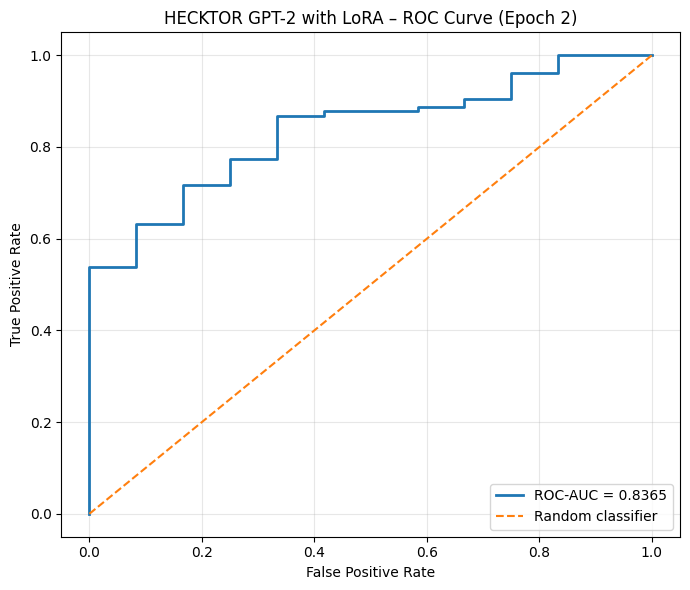

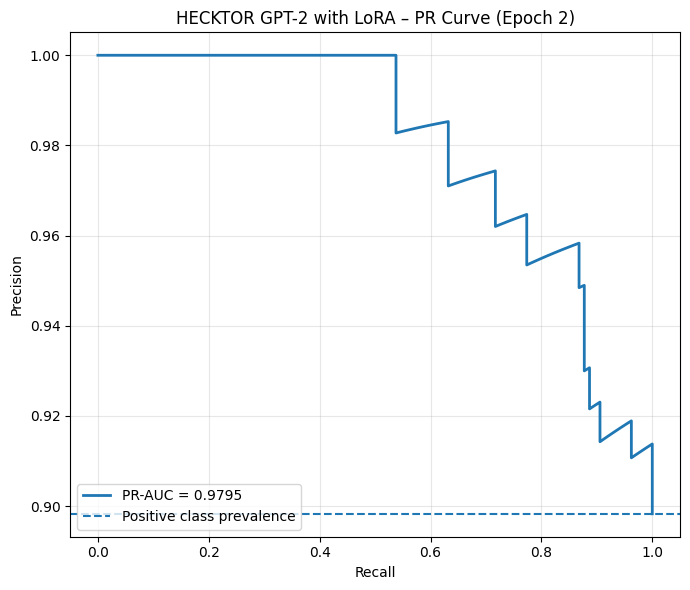

Epoch-2 Test ROC-AUC: 0.8365
Epoch-2 Test PR-AUC: 0.9795


In [5]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

# 1. Load the epoch-2 Balanced Accuracy checkpoint
checkpoint_path = (
    "/content/ROC_HECKTOR_GPT2_CLASSIFIER/"
    "best_model_validation_balanced_accuracy.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# 2. Recreate the exact original model
model = HPVNetGPT2Text().to(device)

# 3. Load all trained GPT-2 LoRA and classifier weights
model.load_state_dict(checkpoint, strict=True)
model.eval()

print("Epoch-2 checkpoint loaded successfully.")

# 4. Generate predictions on the original test set
y_true = []
y_scores = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        logits = model(input_ids, attention_mask)

        probabilities = torch.softmax(logits, dim=1)[:, 1]

        y_scores.extend(probabilities.cpu().numpy())
        y_true.extend(batch["label"].numpy())

y_true = np.asarray(y_true)
y_scores = np.asarray(y_scores)

# 5. Calculate ROC and PR curves
fpr, tpr, _ = roc_curve(y_true, y_scores)
roc_auc_value = auc(fpr, tpr)

precision, recall, _ = precision_recall_curve(y_true, y_scores)
pr_auc_value = average_precision_score(y_true, y_scores)

# 6. Plot ROC curve
plt.figure(figsize=(7, 6))
plt.plot(
    fpr, tpr,
    linewidth=2,
    label=f"ROC-AUC = {roc_auc_value:.4f}"
)
plt.plot([0, 1], [0, 1], "--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HECKTOR GPT-2 with LoRA – ROC Curve (Epoch 2)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/ROC_HECKTOR_GPT2_CLASSIFIER/ROC_Epoch_2.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 7. Plot Precision-Recall curve
plt.figure(figsize=(7, 6))
plt.plot(
    recall, precision,
    linewidth=2,
    label=f"PR-AUC = {pr_auc_value:.4f}"
)
plt.axhline(
    y=np.mean(y_true),
    linestyle="--",
    label="Positive class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("HECKTOR GPT-2 with LoRA – PR Curve (Epoch 2)")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/ROC_HECKTOR_GPT2_CLASSIFIER/PR_Epoch_2.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Epoch-2 Test ROC-AUC: {roc_auc_value:.4f}")
print(f"Epoch-2 Test PR-AUC: {pr_auc_value:.4f}")

In [7]:
# ============================================================
# 3-FOLD STRATIFIED CROSS-VALIDATION
# GPT-2 + LoRA HPV CLASSIFICATION
# Results: MEAN ± SD across 3 folds
# ============================================================

import os
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from transformers import GPT2Tokenizer, GPT2Model
from peft import LoraConfig, get_peft_model, TaskType

# -----------------------------
# 1. CONFIGURATION
# -----------------------------

SEED = 42
N_SPLITS = 3

MODEL_NAME = "openai-community/gpt2"

BATCH_SIZE = 64
EPOCHS = 500
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
MAX_LENGTH = 64

OUTPUT_DIR = "/content/HECKTOR_GPT2_LORA_3FOLD"
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# -----------------------------
# 2. DATASET
# -----------------------------

# Assumes df has already been loaded and HPV_Label created.
# 0 = HPV-negative; 1 = HPV-positive.

FEATURES = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

required_columns = FEATURES + ["HPV_Label"]
missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns in df: {missing_columns}")

data = df[required_columns].copy()
data["HPV_Label"] = pd.to_numeric(
    data["HPV_Label"], errors="coerce"
)
data = data.dropna(subset=["HPV_Label"]).reset_index(drop=True)
data["HPV_Label"] = data["HPV_Label"].astype(int)

if not set(data["HPV_Label"].unique()).issubset({0, 1}):
    raise ValueError("HPV_Label must contain only 0 and 1.")

print("\nFull labelled dataset:", data.shape)
print("Class distribution:")
print(data["HPV_Label"].value_counts().sort_index())

# -----------------------------
# 3. TOKENIZER
# -----------------------------

tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# -----------------------------
# 4. FOLD-SPECIFIC PREPROCESSING
# -----------------------------

def fit_and_apply_imputation(train_df, val_df):

    train_df = train_df.copy()
    val_df = val_df.copy()

    # Age: numeric median fitted on training fold only
    train_df["Age"] = pd.to_numeric(
        train_df["Age"], errors="coerce"
    )
    val_df["Age"] = pd.to_numeric(
        val_df["Age"], errors="coerce"
    )

    age_median = train_df["Age"].median()
    if pd.isna(age_median):
        age_median = 0

    train_df["Age"] = train_df["Age"].fillna(age_median)
    val_df["Age"] = val_df["Age"].fillna(age_median)

    # Other variables: training-fold mode
    categorical_features = [c for c in FEATURES if c != "Age"]

    for col in categorical_features:

        train_df[col] = train_df[col].replace(
            r"^\s*$", np.nan, regex=True
        )
        val_df[col] = val_df[col].replace(
            r"^\s*$", np.nan, regex=True
        )

        train_df[col] = train_df[col].replace(
            ["nan", "None", "NaN"], np.nan
        )
        val_df[col] = val_df[col].replace(
            ["nan", "None", "NaN"], np.nan
        )

        modes = train_df[col].mode(dropna=True)
        fill_value = modes.iloc[0] if len(modes) else "Unknown"

        train_df[col] = train_df[col].fillna(fill_value)
        val_df[col] = val_df[col].fillna(fill_value)

    return train_df, val_df


# -----------------------------
# 5. PROMPT GENERATION
# -----------------------------

def make_prompt(row):

    return (
        "Clinical information for a head and neck cancer patient:\n"
        f"Age: {row['Age']}\n"
        f"Gender: {row['Gender']}\n"
        f"Tobacco Consumption: {row['Tobacco Consumption']}\n"
        f"Alcohol Consumption: {row['Alcohol Consumption']}\n"
        f"Performance Status: {row['Performance Status']}\n"
        f"T-stage: {row['T-stage']}\n"
        f"N-stage: {row['N-stage']}\n"
        f"M-stage: {row['M-stage']}\n"
        "Predict the HPV status. "
        "The answer is either HPV positive or HPV negative."
    )


class HPVTextDataset(Dataset):

    def __init__(self, dataframe):

        self.prompts = [
            make_prompt(row)
            for _, row in dataframe.iterrows()
        ]

        self.labels = dataframe["HPV_Label"].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        encoded = tokenizer(
            self.prompts[idx],
            max_length=MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "label": torch.tensor(self.labels[idx], dtype=torch.long)
        }


# -----------------------------
# 6. MODEL: GPT-2 + LoRA
# -----------------------------

class HPVNetGPT2Text(nn.Module):

    def __init__(self):

        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        # EXACT LoRA SETTINGS FROM YOUR MODEL
        lora_config = LoraConfig(
            r=6,
            lora_alpha=12,
            target_modules=["c_attn"],
            lora_dropout=0.0,
            bias="none",
            task_type=TaskType.FEATURE_EXTRACTION
        )

        self.gpt2 = get_peft_model(self.gpt2, lora_config)

        hidden_size = self.gpt2.config.hidden_size

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(DROPOUT),
            nn.Linear(hidden_size, 128),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        )

        hidden_states = outputs.last_hidden_state

        last_positions = attention_mask.sum(dim=1) - 1

        pooled_output = hidden_states[
            torch.arange(hidden_states.size(0), device=hidden_states.device),
            last_positions
        ]

        return self.classifier(pooled_output)


# -----------------------------
# 7. VALIDATION AND THRESHOLD
# -----------------------------

def get_predictions(model, loader):

    model.eval()

    y_true = []
    y_scores = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            logits = model(input_ids, attention_mask)
            probabilities = torch.softmax(logits, dim=1)[:, 1]

            y_scores.extend(probabilities.cpu().numpy())
            y_true.extend(batch["label"].numpy())

    return np.asarray(y_true), np.asarray(y_scores)


def find_best_threshold(y_true, y_scores):

    candidates = np.unique(
        np.concatenate(([0.0], y_scores, [1.0]))
    )

    best_threshold = 0.5
    best_ba = -1

    for threshold in candidates:

        predictions = (y_scores >= threshold).astype(int)

        ba = balanced_accuracy_score(y_true, predictions)

        if ba > best_ba:
            best_ba = ba
            best_threshold = threshold

    return best_threshold, best_ba


# -----------------------------
# 8. THREE-FOLD CROSS-VALIDATION
# -----------------------------

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

fold_results = []
oof_predictions = []

for fold, (train_indices, val_indices) in enumerate(
    skf.split(data[FEATURES], data["HPV_Label"]), start=1
):

    print("\n" + "=" * 65)
    print(f"FOLD {fold}/{N_SPLITS}")
    print("=" * 65)

    set_seed(SEED + fold)

    train_df = data.iloc[train_indices].copy()
    val_df = data.iloc[val_indices].copy()

    # Fit imputation on training fold only
    train_df, val_df = fit_and_apply_imputation(
        train_df, val_df
    )

    print("Training samples:", len(train_df))
    print("Validation samples:", len(val_df))
    print("Training classes:")
    print(train_df["HPV_Label"].value_counts().sort_index())

    train_dataset = HPVTextDataset(train_df)
    val_dataset = HPVTextDataset(val_df)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    # New model for every fold
    model = HPVNetGPT2Text().to(device)

    # Class weights calculated from training fold only
    class_counts = np.bincount(
        train_df["HPV_Label"].values, minlength=2
    )

    class_weights = len(train_df) / (
        2.0 * np.maximum(class_counts, 1)
    )

    class_weights = torch.tensor(
        class_weights, dtype=torch.float32
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    best_val_ba = -1
    best_epoch = 0
    best_threshold = 0.5
    best_state = None

    for epoch in range(1, EPOCHS + 1):

        model.train()
        running_loss = 0.0

        for batch in train_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            optimizer.zero_grad()

            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / max(len(train_loader), 1)

        # Validation
        val_true, val_scores = get_predictions(
            model, val_loader
        )

        threshold, val_ba = find_best_threshold(
            val_true, val_scores
        )

        if val_ba > best_val_ba:

            best_val_ba = val_ba
            best_epoch = epoch
            best_threshold = threshold
            best_state = copy.deepcopy(model.state_dict())

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Fold {fold} | Epoch {epoch:03d}/{EPOCHS} "
                f"| Train Loss: {train_loss:.4f} "
                f"| Validation BA: {val_ba:.4f} "
                f"| Best BA: {best_val_ba:.4f}"
            )

    # -------------------------
    # 9. EVALUATE BEST CHECKPOINT
    # -------------------------

    model.load_state_dict(best_state, strict=True)

    y_true, y_scores = get_predictions(model, val_loader)

    predictions = (y_scores >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    sensitivity = tp / (tp + fn) if (tp + fn) else 0.0

    roc_auc = roc_auc_score(y_true, y_scores)
    pr_auc = average_precision_score(y_true, y_scores)

    fold_metrics = {
        "Fold": fold,
        "Best_Epoch": best_epoch,
        "Threshold": best_threshold,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1": f1_score(
            y_true, predictions, zero_division=0
        )
    }

    fold_results.append(fold_metrics)

    # Save best model for this fold
    checkpoint_path = os.path.join(
        OUTPUT_DIR, f"best_model_fold_{fold}.pth"
    )

    torch.save(best_state, checkpoint_path)

    # Save out-of-fold predictions
    for i in range(len(y_true)):

        oof_predictions.append({
            "Fold": fold,
            "True_Label": int(y_true[i]),
            "Predicted_Probability": float(y_scores[i]),
            "Predicted_Label": int(predictions[i]),
            "Threshold": float(best_threshold)
        })

    print(f"\nFold {fold} results:")
    print(f"Best epoch: {best_epoch}")
    print(f"Best validation threshold: {best_threshold:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"PR-AUC: {pr_auc:.4f}")
    print(
        f"Balanced accuracy: "
        f"{fold_metrics['Balanced_Accuracy']:.4f}"
    )
    print(f"Sensitivity: {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"F1-score: {fold_metrics['F1']:.4f}")

    del model, optimizer, criterion
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


### 10. Mean ± SD across the three folds


# ============================================================
# 10. RESULTS: MEAN ± STANDARD DEVIATION
# ============================================================

results_df = pd.DataFrame(fold_results)

metrics = [
    "ROC_AUC",
    "PR_AUC",
    "Balanced_Accuracy",
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1"
]

summary_rows = []

for metric in metrics:

    mean_value = results_df[metric].mean()
    sd_value = results_df[metric].std(ddof=1)

    summary_rows.append({
        "Metric": metric,
        "Mean": mean_value,
        "SD": sd_value,
        "Mean ± SD": f"{mean_value:.4f} ± {sd_value:.4f}"
    })

summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 65)
print("3-FOLD CROSS-VALIDATION RESULTS")
print("MEAN ± STANDARD DEVIATION")
print("=" * 65)

print(summary_df[["Metric", "Mean ± SD"]].to_string(index=False))

# Save fold-level and summary results
results_df.to_csv(
    os.path.join(OUTPUT_DIR, "3fold_results_by_fold.csv"),
    index=False
)

summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "3fold_results_mean_sd.csv"),
    index=False
)

oof_df = pd.DataFrame(oof_predictions)

oof_df.to_csv(
    os.path.join(OUTPUT_DIR, "3fold_out_of_fold_predictions.csv"),
    index=False
)

print("\nFiles saved in:", OUTPUT_DIR)

# Display fold-level results
print("\nIndividual fold results:")
display(results_df)

# Display mean ± SD
print("\nMean ± SD:")
display(summary_df)

Device: cuda

Full labelled dataset: (588, 9)
Class distribution:
HPV_Label
0     58
1    530
Name: count, dtype: int64

FOLD 1/3
Training samples: 392
Validation samples: 196
Training classes:
HPV_Label
0     39
1    353
Name: count, dtype: int64


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


Fold 1 | Epoch 001/500 | Train Loss: 0.7075 | Validation BA: 0.6725 | Best BA: 0.6725
Fold 1 | Epoch 010/500 | Train Loss: 0.6667 | Validation BA: 0.7169 | Best BA: 0.7169
Fold 1 | Epoch 020/500 | Train Loss: 0.5464 | Validation BA: 0.7168 | Best BA: 0.7310
Fold 1 | Epoch 030/500 | Train Loss: 0.5050 | Validation BA: 0.7139 | Best BA: 0.7310
Fold 1 | Epoch 040/500 | Train Loss: 0.5183 | Validation BA: 0.7440 | Best BA: 0.7440
Fold 1 | Epoch 050/500 | Train Loss: 0.4647 | Validation BA: 0.7553 | Best BA: 0.7694
Fold 1 | Epoch 060/500 | Train Loss: 0.4392 | Validation BA: 0.7422 | Best BA: 0.7694
Fold 1 | Epoch 070/500 | Train Loss: 0.4502 | Validation BA: 0.7478 | Best BA: 0.7957
Fold 1 | Epoch 080/500 | Train Loss: 0.4897 | Validation BA: 0.7291 | Best BA: 0.7957
Fold 1 | Epoch 090/500 | Train Loss: 0.4567 | Validation BA: 0.7638 | Best BA: 0.7957
Fold 1 | Epoch 100/500 | Train Loss: 0.4654 | Validation BA: 0.7319 | Best BA: 0.7957
Fold 1 | Epoch 110/500 | Train Loss: 0.4456 | Validati

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/tuners/lora/layer.py:2760: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


... (3 outputs left out)

Fold 3 | Epoch 001/500 | Train Loss: 0.6835 | Validation BA: 0.5773 | Best BA: 0.5773
Fold 3 | Epoch 010/500 | Train Loss: 0.6977 | Validation BA: 0.7034 | Best BA: 0.7773
Fold 3 | Epoch 020/500 | Train Loss: 0.6276 | Validation BA: 0.8142 | Best BA: 0.8250
Fold 3 | Epoch 030/500 | Train Loss: 0.6060 | Validation BA: 0.8023 | Best BA: 0.8250
Fold 3 | Epoch 040/500 | Train Loss: 0.5271 | Validation BA: 0.8159 | Best BA: 0.8250
Fold 3 | Epoch 050/500 | Train Loss: 0.5483 | Validation BA: 0.8125 | Best BA: 0.8250
Fold 3 | Epoch 060/500 | Train Loss: 0.5259 | Validation BA: 0.7761 | Best BA: 0.8250
Fold 3 | Epoch 070/500 | Train Loss: 0.4818 | Validation BA: 0.8040 | Best BA: 0.8250
Fold 3 | Epoch 080/500 | Train Loss: 0.4373 | Validation BA: 0.7438 | Best BA: 0.8250
Fold 3 | Epoch 090/500 | Train Loss: 0.4451 | Validation BA: 0.7216 | Best BA: 0.8250
Fold 3 | Epoch 100/500 | Train Loss: 0.4643 | Validation BA: 0.7545 | Best BA: 0.8250
Fold 3 | Epoch 110/500 | Train Loss: 0.4615 | Validati

,Fold,Best_Epoch,Threshold,ROC_AUC,PR_AUC,Balanced_Accuracy,Accuracy,Precision,Sensitivity,Specificity,F1
0,1,106,0.585139,0.796461,0.974160,0.804193,0.688776,0.991525,0.661017,0.947368,0.793220
1,2,46,0.629802,0.775052,0.967373,0.780702,0.688776,0.983333,0.666667,0.894737,0.794613
2,3,15,0.588507,0.827699,0.975541,0.825000,0.765306,0.985075,0.750000,0.900000,0.851613



Mean ± SD:


,Metric,Mean,SD,Mean ± SD
0,ROC_AUC,0.799737,0.026476,0.7997 ± 0.0265
1,PR_AUC,0.972358,0.004372,0.9724 ± 0.0044
2,Balanced_Accuracy,0.803298,0.022163,0.8033 ± 0.0222
3,Accuracy,0.714286,0.044185,0.7143 ± 0.0442
4,Precision,0.986644,0.004316,0.9866 ± 0.0043
5,Sensitivity,0.692561,0.049824,0.6926 ± 0.0498
6,Specificity,0.914035,0.028987,0.9140 ± 0.0290
7,F1,0.813149,0.033318,0.8131 ± 0.0333
